# Khảo sát dữ liệu với pandas, NumPy và matplotlib

Notebook độc lập, không import mã dự án, không tải dữ liệu và không huấn luyện. Chạy từ trên xuống bằng kernel có pandas, NumPy, matplotlib. Trong Jupyter dùng biểu đồ inline để không chờ cửa sổ đồ họa.

Dữ liệu nguồn là `data/raw`. Trước khi phân tích, chuẩn hóa giống dự án: Unicode NFC, chữ thường, gộp khoảng trắng. Không tự xóa câu, sửa chính tả hoặc thay nhãn. Các thống kê dưới đây áp dụng cho văn bản sau chuẩn hóa.

## Lựa chọn biểu đồ và lý do

| Nội dung | Biểu đồ | Lý do |
|---|---|---|
| Quy mô train/validation/test | Cột đứng | So sánh số lượng chính xác trên cùng một trục |
| Tỷ lệ nhãn giữa các tập | Cột chồng 100% | Loại ảnh hưởng do kích thước tập khác nhau; nhãn ít mẫu vẫn có tỷ lệ ghi rõ |
| Độ dài câu | Histogram với cùng khoảng chia | Thấy vùng tập trung và đuôi dài; dùng phần trăm để so sánh các tập |
| Cảm xúc theo chủ đề trong train | Heatmap phần trăm theo hàng | Thấy quan hệ hai nhãn; kèm số lượng để tránh hiểu nhầm nhóm ít mẫu |

Không dùng biểu đồ tròn vì khó so sánh nhiều tập; không dùng word cloud vì kích thước chữ khó đọc thành số liệu và cần thêm thư viện.


In [9]:

%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [10]:
from pathlib import Path
import unicodedata
import time
import pandas as pd
import numpy as np
import matplotlib

# Jupyter có sẵn get_ipython; không cần import IPython trong notebook.
try:
    get_ipython().run_line_magic('matplotlib', 'inline')
except NameError:
    matplotlib.use('Agg')  # Cho phép kiểm tra bằng Python không có giao diện.
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 100, 'font.family': 'DejaVu Sans'})
started = time.perf_counter()
SPLITS = ('train', 'validation', 'test')
SENTIMENT = {'0': 'Tiêu cực', '1': 'Trung lập', '2': 'Tích cực'}
TOPIC = {'0': 'Giảng viên', '1': 'Chương trình học', '2': 'Cơ sở vật chất', '3': 'Khác'}
candidates = [base / suffix / 'data/raw'
              for base in [Path.cwd(), *Path.cwd().parents]
              for suffix in ('', 'student_feedback', 'student-feedback-ai/student_feedback')]
RAW = next((p for p in candidates if (p / 'train/sents.txt').is_file()), None)
if RAW is None:
    raise FileNotFoundError('Không tìm thấy data/raw. Mở notebook từ workspace hoặc student_feedback.')

def read_lines(path):
    with path.open(encoding='utf-8-sig') as stream:
        return [line.removesuffix('\n') for line in stream]

def normalize(text):
    return ' '.join(unicodedata.normalize('NFC', text).lower().split())

frames = []
for split in SPLITS:
    folder = RAW / split
    if split == 'validation' and not folder.exists():
        folder = RAW / 'dev'
    texts, sentiments, topics = [read_lines(folder / f) for f in ('sents.txt', 'sentiments.txt', 'topics.txt')]
    if not texts or len({len(texts), len(sentiments), len(topics)}) != 1:
        raise ValueError(f'{split}: rỗng hoặc số dòng văn bản/nhãn không khớp')
    if set(sentiments) - SENTIMENT.keys() or set(topics) - TOPIC.keys():
        raise ValueError(f'{split}: mã nhãn không hợp lệ')
    frames.append(pd.DataFrame({'split': split, 'raw_text': texts,
                               'sentiment': [SENTIMENT[x] for x in sentiments],
                               'topic': [TOPIC[x] for x in topics]}))
df = pd.concat(frames, ignore_index=True)
df['text'] = df.raw_text.map(normalize)
df['characters'] = df.text.str.len()
df['units'] = df.text.str.split().str.len()
print(f'Đã đọc {len(df):,} câu trong {time.perf_counter()-started:.2f}s. Nguồn: {RAW}')
print(df.groupby('split', sort=False).head(2).to_string(index=False))


Đã đọc 16,175 câu trong 0.11s. Nguồn: d:\N.ThanhNhan\Project_AI\student-feedback-ai\student-feedback-ai\student_feedback\data\raw
     split                                       raw_text sentiment            topic                                           text  characters  units
     train                      slide giáo trình đầy đủ .  Tích cực Chương trình học                      slide giáo trình đầy đủ .          25      6
     train nhiệt tình giảng dạy , gần gũi với sinh viên .  Tích cực       Giảng viên nhiệt tình giảng dạy , gần gũi với sinh viên .          46     11
validation                       giáo trình chưa cụ thể .  Tiêu cực Chương trình học                       giáo trình chưa cụ thể .          24      6
validation                               giảng buồn ngủ .  Tiêu cực       Giảng viên                               giảng buồn ngủ .          16      4
      test                       nói tiếng anh lưu loát .  Tích cực       Giảng viên                       nói tiến

## 1. Quy mô dữ liệu — biểu đồ cột
Số lượng trên đầu mỗi cột giúp đọc giá trị cụ thể.


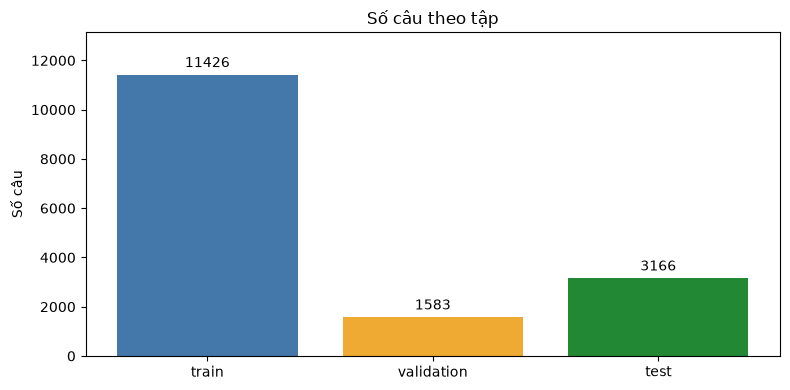

Tỷ lệ từng tập (%): {'train': 70.6, 'validation': 9.8, 'test': 19.6}
Nhận xét: train cung cấp mẫu học; validation dùng chọn cấu hình; test dành cho đánh giá cuối.


In [11]:
sizes = df.groupby('split').size().reindex(SPLITS)
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(sizes.index, sizes.values, color=['#4477AA', '#EEAA33', '#228833'])
ax.bar_label(bars, padding=3)
ax.set(title='Số câu theo tập', ylabel='Số câu', ylim=(0, sizes.max()*1.15))
fig.tight_layout()
plt.show()
plt.close(fig)
print('Tỷ lệ từng tập (%):', (sizes / sizes.sum() * 100).round(1).to_dict())
print('Nhận xét: train cung cấp mẫu học; validation dùng chọn cấu hình; test dành cho đánh giá cuối.')


### Nhận xét phân tích — quy mô
Bộ dữ liệu hiện tại có **16.175 câu**: train **11.426 (70,6%)**, validation **1.583 (9,8%)**, test **3.166 (19,6%)**. Có thể dùng cách chia sẵn để so sánh các mô hình có giám sát. Tuy nhiên, tổng số câu không cho biết độ đa dạng ngôn ngữ hoặc chất lượng nhãn; chưa có cơ sở khẳng định dữ liệu đủ cho mọi mô hình. Các con số trong phần nhận xét là ảnh chụp dữ liệu hiện tại; bảng tính phía trên là nguồn đối chiếu nếu dữ liệu thay đổi.


## 2. Phân bố nhãn — cột chồng 100%
Mỗi cột luôn bằng 100%. Bảng bên dưới giữ số lượng gốc để phân biệt tỷ lệ tương đương với lượng dữ liệu thực tế khác nhau.



sentiment — số lượng:
sentiment   Tiêu cực  Trung lập  Tích cực
split                                    
train           5325        458      5643
validation       705         73       805
test            1409        167      1590
Tỷ lệ (%):
sentiment   Tiêu cực  Trung lập  Tích cực
split                                    
train          46.60       4.01     49.39
validation     44.54       4.61     50.85
test           44.50       5.27     50.22
Nhận xét: lớp lớn nhất chiếm 49.4% train; lớp ít nhất có 458 mẫu. Cần theo dõi Macro-F1 và recall từng lớp.

topic — số lượng:
topic       Giảng viên  Chương trình học  Cơ sở vật chất  Khác
split                                                         
train             8166              2201             497   562
validation        1151               267              70    95
test              2290               572             145   159
Tỷ lệ (%):
topic       Giảng viên  Chương trình học  Cơ sở vật chất  Khác
split                         

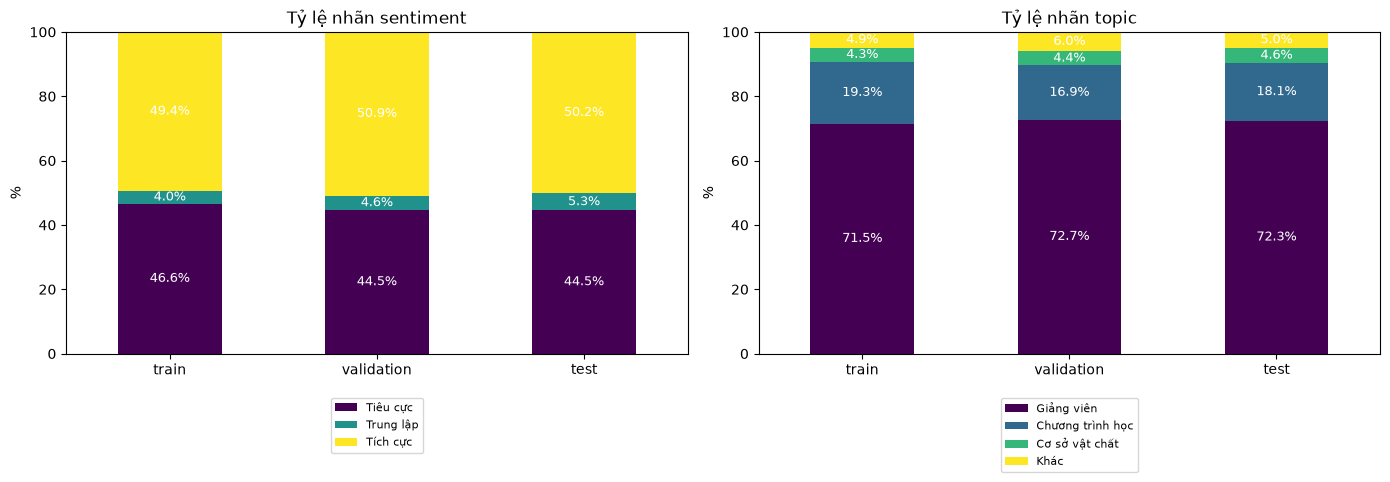

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, task, labels in zip(axes, ['sentiment', 'topic'], [SENTIMENT, TOPIC]):
    counts = pd.crosstab(df.split, df[task]).reindex(index=SPLITS, columns=list(labels.values()), fill_value=0)
    pct = counts.div(sizes, axis=0) * 100
    pct.plot.bar(stacked=True, ax=ax, rot=0, colormap='viridis')
    for container in ax.containers:
        ax.bar_label(container, labels=[f'{v:.1f}%' if v >= 3 else '' for v in container.datavalues],
                     label_type='center', color='white', fontsize=9)
    ax.set(title=f'Tỷ lệ nhãn {task}', ylabel='%', xlabel='', ylim=(0, 100))
    ax.legend(loc='upper center', bbox_to_anchor=(.5, -.12), fontsize=8)
    print(f'\n{task} — số lượng:\n{counts.to_string()}')
    print(f'Tỷ lệ (%):\n{pct.round(2).to_string()}')
    train_counts = counts.loc['train']
    print(f'Nhận xét: lớp lớn nhất chiếm {pct.loc["train"].max():.1f}% train; '
          f'lớp ít nhất có {train_counts.min():,} mẫu. Cần theo dõi Macro-F1 và recall từng lớp.')
fig.tight_layout()
plt.show()
plt.close(fig)


### Nhận xét phân tích — lệch nhãn
- **Cảm xúc:** train có 5.643 tích cực, 5.325 tiêu cực và chỉ **458 trung lập (4,0%)**. Hai cực khá cân bằng nhưng lớp trung lập thiếu mẫu tương đối; không nên gọi toàn bộ bài toán là cân bằng. Validation chỉ có **73 câu trung lập**, nên kết quả lớp này có thể dao động đáng kể.
- **Chủ đề:** giảng viên chiếm **71,5%** train (8.166 câu), chương trình học **19,3%**, khác **4,9%**, cơ sở vật chất **4,3%**. Luôn đoán giảng viên đã đạt 71,5% accuracy trên train, nhưng không nhận diện được các lớp còn lại. Đây là mốc đoán nhãn đa số, không phải chất lượng AI.
- Phân bố giữa các tập nhìn chung gần nhau, nhưng điều này không chứng minh văn phong hoặc ngữ nghĩa giống nhau. Cần ưu tiên **Macro-F1**, kèm recall từng lớp; thử trọng số lớp trên validation, không mặc định rằng cân bằng trọng số sẽ cải thiện mọi chỉ số.

**Mục 1–2 đủ nhận xét quy mô và mất cân bằng, chưa đủ đề xuất mô hình có căn cứ về nội dung văn bản.** Mục 3 cho biết độ dài, mục 4 cho biết quan hệ nhãn, mục 5 kiểm tra chất lượng; mục 6 bổ sung tín hiệu từ vựng. Các mục này đủ xây dựng danh sách mô hình thử nghiệm, không đủ chốt mô hình thắng cuộc.


## 3. Độ dài — histogram cùng khoảng chia
Số đơn vị cách trắng không phải số từ hoặc số token của mô hình tiếng Việt. Chỉ vẽ đến P99 để đuôi dài không ép các cột còn lại; phần bị cắt được báo riêng. Trục dọc là phần trăm **tổng số câu của tập**, không chuẩn hóa lại sau khi cắt.


           characters                                              units                                         
                count  mean   std  min   25%   50%   75%    max    count  mean   std  min  25%   50%   75%    max
split                                                                                                            
test           3166.0  58.8  44.1  4.0  30.0  46.0  73.0  411.0   3166.0  14.2  10.2  2.0  8.0  11.0  17.0   98.0
train         11426.0  59.1  43.1  4.0  31.0  47.0  73.0  660.0  11426.0  14.3  10.1  2.0  8.0  11.0  17.0  159.0
validation     1583.0  56.4  42.8  4.0  31.0  45.0  69.0  718.0   1583.0  13.7   9.9  2.0  8.0  11.0  17.0  161.0
characters, train: 115 câu vượt giới hạn hiển thị 218.0
characters, validation: 11 câu vượt giới hạn hiển thị 218.0
characters, test: 34 câu vượt giới hạn hiển thị 218.0
units, train: 111 câu vượt giới hạn hiển thị 52.0
units, validation: 11 câu vượt giới hạn hiển thị 52.0
units, test: 32 câu vượt giới hạn hiển thị

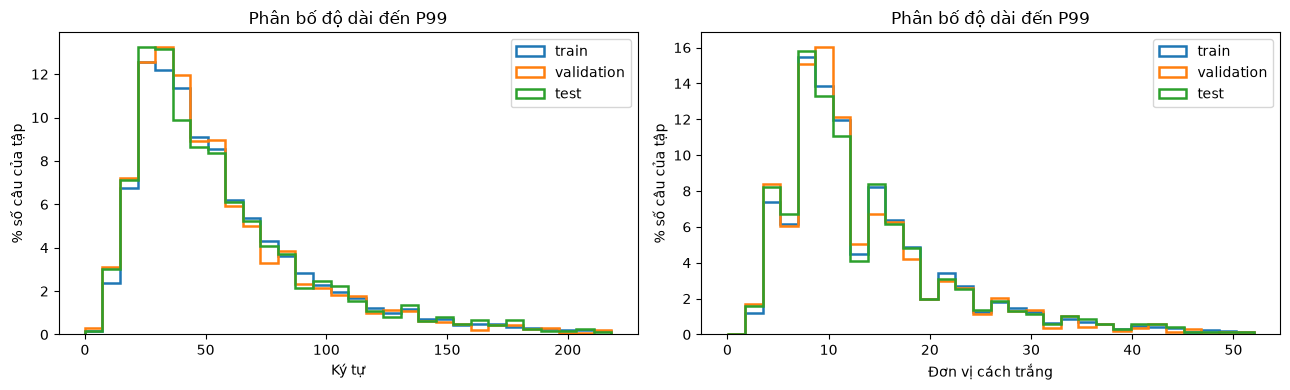

Nhận xét: câu ngắn có thể thiếu ngữ cảnh; câu dài cần kiểm tra nguy cơ bị cắt. Muốn chọn max_length cho mô hình phải đo lại bằng tokenizer trên train.


In [13]:
print(df.groupby('split')[['characters', 'units']].describe().round(1).to_string())
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col, label in zip(axes, ['characters', 'units'], ['Ký tự', 'Đơn vị cách trắng']):
    cap = max(1, float(df[col].quantile(.99)))
    bins = np.linspace(0, cap, 31)
    for split in SPLITS:
        values = df.loc[df.split.eq(split), col].to_numpy()
        ax.hist(values, bins=bins, weights=np.full(len(values), 100/len(values)),
                histtype='step', linewidth=1.8, label=split)
        print(f'{col}, {split}: {(values > cap).sum()} câu vượt giới hạn hiển thị {cap:.1f}')
    ax.set(xlabel=label, ylabel='% số câu của tập', title='Phân bố độ dài đến P99')
    ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)
print('Nhận xét: câu ngắn có thể thiếu ngữ cảnh; câu dài cần kiểm tra nguy cơ bị cắt. '
      'Muốn chọn max_length cho mô hình phải đo lại bằng tokenizer trên train.')


### Nhận xét phân tích — độ dài
Train có trung vị **47 ký tự**, P99 **219 ký tự**: ít nhất khoảng một nửa số câu không dài hơn 47 ký tự. Đây là lý do hợp lý để thử biểu diễn TF-IDF trên các cụm ngắn trước. Tuy nhiên, câu ngắn vẫn có thể chứa phủ định hoặc thiếu ngữ cảnh; độ dài không chứng minh bài toán dễ hay tuyến tính. Nếu thử Transformer, cần đo độ dài bằng tokenizer riêng, không đổi trực tiếp số ký tự thành `max_length`.


## 4. Quan hệ hai nhãn — heatmap trên train
Màu thể hiện tỷ lệ cảm xúc **trong mỗi chủ đề**. Mỗi ô ghi cả số mẫu và tỷ lệ; tổng mỗi hàng bằng 100%. Quan hệ này mô tả dữ liệu, không chứng minh quan hệ nhân quả.


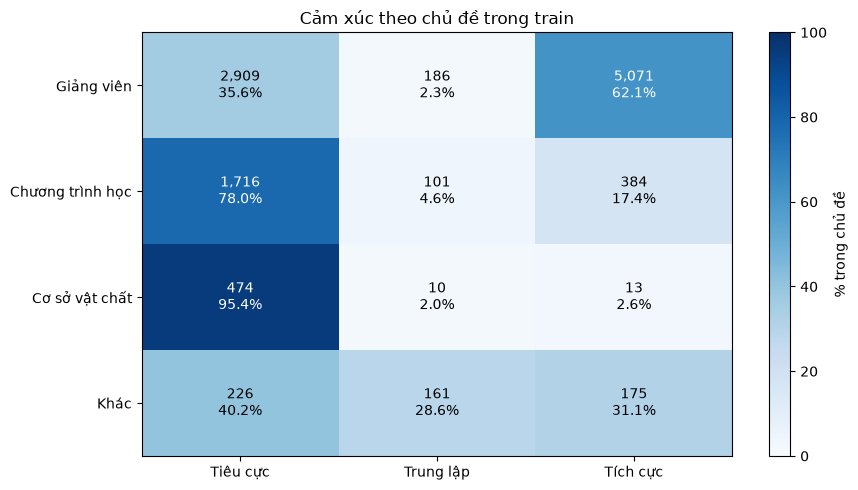

Nhận xét: các nhóm có ít mẫu cần được xem cùng số lượng tuyệt đối; không dùng nhãn chủ đề thật làm đầu vào dự đoán cảm xúc nếu triển khai không có nhãn đó.


In [14]:
train = df[df.split.eq('train')]
counts = pd.crosstab(train.topic, train.sentiment).reindex(
    index=list(TOPIC.values()), columns=list(SENTIMENT.values()), fill_value=0)
pct = counts.div(counts.sum(axis=1).replace(0, np.nan), axis=0).mul(100).fillna(0)
fig, ax = plt.subplots(figsize=(9, 5))
im = ax.imshow(pct.to_numpy(), vmin=0, vmax=100, cmap='Blues', aspect='auto')
ax.set_xticks(np.arange(len(counts.columns)), counts.columns)
ax.set_yticks(np.arange(len(counts.index)), counts.index)
for row in range(len(counts)):
    for col in range(len(counts.columns)):
        value = pct.iloc[row, col]
        ax.text(col, row, f'{counts.iloc[row,col]:,}\n{value:.1f}%', ha='center', va='center',
                color='white' if value > 55 else 'black')
ax.set_title('Cảm xúc theo chủ đề trong train')
fig.colorbar(im, ax=ax, label='% trong chủ đề')
fig.tight_layout()
plt.show()
plt.close(fig)
print('Nhận xét: các nhóm có ít mẫu cần được xem cùng số lượng tuyệt đối; '
      'không dùng nhãn chủ đề thật làm đầu vào dự đoán cảm xúc nếu triển khai không có nhãn đó.')


## 5. Kiểm tra chất lượng và nhận xét tổng hợp
Dùng bảng thay vì biểu đồ vì số lượng lỗi nhỏ cần đọc chính xác. Trùng được tính sau chuẩn hóa; không tự xóa hoặc đổi nhãn.


In [15]:
quality = pd.DataFrame([{
    'split': split, 'rows': len(g), 'empty': int(g.text.eq('').sum()),
    'changed': int(g.raw_text.ne(g.text).sum()),
    'extra_duplicates': int(g.text.duplicated().sum()),
    'short_le_2_units': int(g.units.le(2).sum())
} for split in SPLITS for g in [df[df.split.eq(split)]]]).set_index('split')
print(quality.to_string())
print('extra_duplicates: số bản sao dư; changed: số câu thay đổi sau chuẩn hóa.')
for i, left in enumerate(SPLITS):
    for right in SPLITS[i+1:]:
        overlap = set(df.loc[df.split.eq(left), 'text']) & set(df.loc[df.split.eq(right), 'text'])
        print(f'{left} / {right}: {len(overlap):,} văn bản duy nhất trùng')
conflicts = df.groupby('text')[['sentiment', 'topic']].nunique().gt(1).sum()
print('Số văn bản có nhiều nhãn khác nhau:', conflicts.to_dict())
print(f'Nhận xét: {quality["empty"].sum()} câu rỗng; '
      f'{quality.extra_duplicates.sum()} bản sao dư trong các tập. '
      'Cần rà soát câu có nhãn mâu thuẫn trước khi quyết định xử lý.')


             rows  empty  changed  extra_duplicates  short_le_2_units
split                                                                
train       11426      0        5                 1                21
validation   1583      0        0                 0                 5
test         3166      0        3                 0                 5
extra_duplicates: số bản sao dư; changed: số câu thay đổi sau chuẩn hóa.
train / validation: 0 văn bản duy nhất trùng
train / test: 0 văn bản duy nhất trùng
validation / test: 0 văn bản duy nhất trùng
Số văn bản có nhiều nhãn khác nhau: {'sentiment': 1, 'topic': 0}
Nhận xét: 0 câu rỗng; 1 bản sao dư trong các tập. Cần rà soát câu có nhãn mâu thuẫn trước khi quyết định xử lý.


### Nhận xét phân tích — chất lượng
Dữ liệu hiện tại có **0 câu rỗng sau chuẩn hóa**, **1 bản sao dư trong tập**, **1 văn bản có nhãn cảm xúc mâu thuẫn**, và **0 văn bản trùng chính xác giữa các tập**. Chưa thấy rò rỉ do trùng chính xác, nhưng chưa kiểm tra câu gần giống hoặc phản hồi từ cùng người/lớp học. Nếu thiếu thông tin nguồn, không thể xác nhận các tập độc lập theo người học. Cần rà soát văn bản mâu thuẫn; không tự động xóa theo nhãn thiểu số.


## 6. Tín hiệu từ vựng — cột ngang cho cụm hai đơn vị trong train

**Vì sao thêm biểu đồ này?** Quy mô, tỷ lệ nhãn và độ dài chưa cho thấy nội dung nào có thể giúp phân loại. Cột ngang dễ đọc cụm tiếng Việt dài. Mỗi biểu đồ hiển thị 6 cụm xuất hiện trong nhiều câu nhất của một lớp, tính **% câu trong lớp có cụm đó**, không đếm lặp nhiều lần trong một câu.

Chỉ dùng train. Tách đơn vị bằng biểu thức chữ/số và ghép hai đơn vị liền nhau; đây **không phải tách từ tiếng Việt**. Không loại từ dừng để giữ từ phủ định như “không”. Cụm phổ biến không đồng nghĩa cụm phân biệt tốt; bảng dưới đối chiếu cùng cụm ở tất cả các lớp.


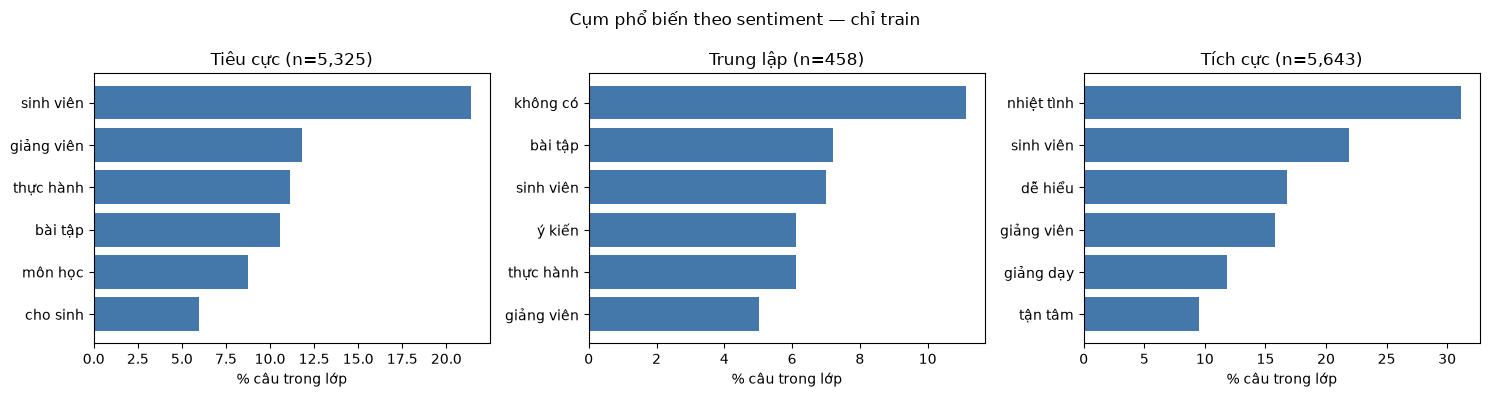


sentiment: % câu chứa cụm, so sánh giữa các lớp
            Tiêu cực  Trung lập  Tích cực
bài tập         10.6        7.2       6.8
cho sinh         6.0        2.4       5.4
dễ hiểu          0.9        0.2      16.8
giảng dạy        4.9        3.5      11.8
giảng viên      11.8        5.0      15.8
không có         3.0       11.1       0.3
môn học          8.7        3.5       2.8
nhiệt tình       1.5        0.4      31.2
sinh viên       21.4        7.0      21.9
thực hành       11.2        6.1       2.2
tận tâm          0.5        0.0       9.5
ý kiến           0.6        6.1       0.5


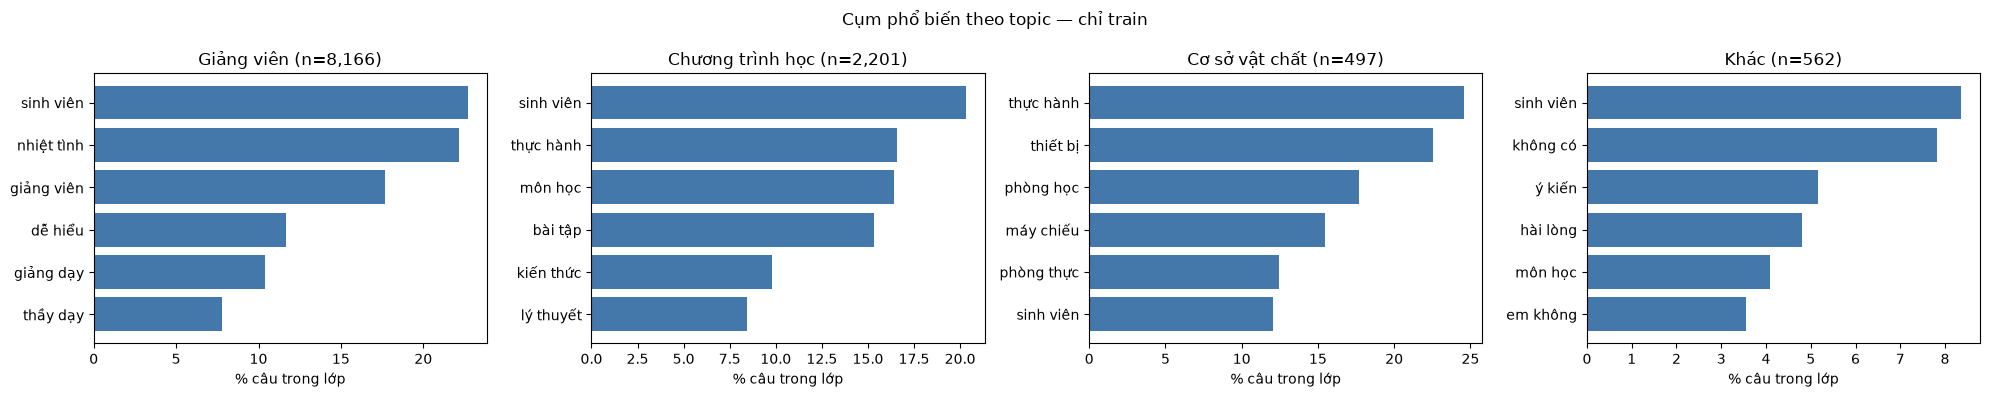


topic: % câu chứa cụm, so sánh giữa các lớp
            Giảng viên  Chương trình học  Cơ sở vật chất  Khác
bài tập            7.7              15.3             1.2   1.8
dễ hiểu           11.7               1.6             0.2   1.4
em không           0.7               0.9             0.6   3.6
giảng dạy         10.4               3.2             4.0   0.9
giảng viên        17.7               3.3             2.6   2.1
hài lòng           0.9               0.4             0.0   4.8
không có           1.3               2.6             3.6   7.8
kiến thức          7.6               9.8             0.2   3.4
lý thuyết          1.9               8.5             0.4   0.7
máy chiếu          0.0               0.2            15.5   0.0
môn học            2.9              16.4             3.2   4.1
nhiệt tình        22.2               0.8             0.4   2.1
phòng học          0.0               0.2            17.7   0.2
phòng thực         0.0               0.2            12.5   0.2
sinh viên 

In [16]:
from collections import Counter
import re
train = df[df.split.eq('train')].copy()
def phrases(text):
    parts = re.findall(r'[^\W_]+', text, flags=re.UNICODE)
    return set(' '.join(parts[i:i+2]) for i in range(len(parts)-1))
train['phrases'] = train.text.map(phrases)
for task in ['sentiment', 'topic']:
    labels = list(SENTIMENT.values()) if task == 'sentiment' else list(TOPIC.values())
    fig, axes = plt.subplots(1, len(labels), figsize=(5*len(labels), 4), squeeze=False)
    tables = {}
    selected = set()
    for ax, label in zip(axes[0], labels):
        group = train[train[task].eq(label)]
        counter = Counter(p for row in group.phrases for p in row)
        rates = pd.Series({p: 100*c/len(group) for p,c in counter.items()}, dtype=float)
        tables[label] = rates
        top = rates.nlargest(6).sort_values()
        selected.update(top.index)
        ax.barh(top.index, top.values, color='#4477AA')
        ax.set(title=f'{label} (n={len(group):,})', xlabel='% câu trong lớp')
    fig.suptitle(f'Cụm phổ biến theo {task} — chỉ train')
    fig.tight_layout()
    plt.show()
    plt.close(fig)
    comparison = pd.DataFrame(tables).reindex(sorted(selected)).fillna(0)
    print(f'\n{task}: % câu chứa cụm, so sánh giữa các lớp\n{comparison.round(1).to_string()}')
print('Cách đọc: cụm có tỷ lệ gần nhau ở nhiều lớp là từ vựng chung; '
      'cụm có tỷ lệ chênh lệch là ứng viên tín hiệu, chưa chứng minh khả năng dự đoán trên dữ liệu mới.')


## 7. Đề xuất mô hình từ góc nhìn phân tích dữ liệu

### Mức độ đủ của bằng chứng
**Đủ để đề xuất thứ tự thử nghiệm; chưa đủ để chốt mô hình tốt nhất.** Thêm nhiều biểu đồ không thay thế đánh giá trên validation. Không cần PCA, t-SNE, word cloud hoặc ma trận tương quan mã nhãn: chúng tăng độ phức tạp mà không trực tiếp giải quyết quyết định hiện tại. Heatmap ở mục 4 là thông tin bổ trợ, không phải bằng chứng bắt buộc để chọn mô hình.

### Danh sách đề xuất và lý do

| Ưu tiên | Ứng viên | Căn cứ và mục đích | Điều chưa thể kết luận |
|---|---|---|---|
| 1 | **TF-IDF + Logistic Regression** | Điểm xuất phát cho hai bài toán riêng: dữ liệu gán nhãn, nhiều câu ngắn; kiểm tra liệu tín hiệu từ/cụm ở mục 6 có đủ hữu ích. Dễ kiểm tra trọng số đặc trưng; có đầu ra xác suất để đánh giá thêm nếu cần. | Xác suất chưa chắc được hiệu chỉnh tốt; chưa biết chất lượng lớp trung lập. |
| 2 | **TF-IDF + Linear SVM (LinearSVC)** | Đối chứng tuyến tính trên cùng đặc trưng thưa; so sánh với Logistic Regression trong cùng điều kiện. | EDA không chứng minh SVM tốt hơn; LinearSVC không trực tiếp cho xác suất. |
| 3, có điều kiện | **Fine-tune PhoBERT** | Ứng viên mô hình tiếng Việt đã tiền huấn luyện nếu phân tích lỗi của hai baseline cho thấy khó khăn về phủ định/ngữ cảnh và có đủ tài nguyên. | Chưa có phân tích lỗi nên chưa thể khẳng định cần Transformer hoặc sẽ tăng điểm. Phải theo đúng bước tách từ/tokenizer của mô hình. |

TF-IDF là cách biểu diễn văn bản, không phải mô hình phân loại. Có thể thử cụm 1–2 đơn vị; chỉ gọi là word n-gram khi đã thực hiện tách từ phù hợp. Character n-gram là phương án bổ sung **nếu** kiểm tra văn bản cho thấy nhiều biến thể chính tả/viết tắt; các biểu đồ hiện tại chưa đo mức nhiễu đó.

Các mô hình tuyến tính với biểu diễn TF-IDF là lựa chọn có căn cứ từ phương pháp phân loại văn bản thưa trong [tài liệu scikit-learn](https://scikit-learn.org/stable/auto_examples/text/plot_document_classification_20newsgroups.html). PhoBERT là mô hình tiền huấn luyện chuyên cho tiếng Việt theo [bài báo gốc](https://aclanthology.org/2020.findings-emnlp.92/) và [hướng dẫn tác giả](https://github.com/VinAIResearch/PhoBERT). **Thứ tự thử nghiệm trên là đề xuất phân tích cho bộ dữ liệu này, không phải kết quả so sánh đã đo.**

### Điều kiện chốt mô hình sau này
1. Huấn luyện bộ phân loại cảm xúc và chủ đề riêng; không đưa nhãn thật của bài toán còn lại vào đầu vào nếu triển khai không có nhãn đó.
2. Chỉ fit từ vựng/IDF và mô hình trên train. So sánh cấu hình mặc định với trọng số lớp trên validation, ưu tiên Macro-F1 và recall lớp hiếm, đồng thời ghi thời gian và tài nguyên.
3. Đọc lỗi nhầm lẫn trung lập–tích cực–tiêu cực và các chủ đề ít mẫu. Kiểm tra một mẫu câu train theo từng nhãn để xác nhận vấn đề ngôn ngữ; biểu đồ từ vựng chưa thay thế đọc nội dung.
4. Chốt cấu hình bằng validation rồi đánh giá test một lần. EDA trên test chỉ mô tả/chẩn đoán chất lượng, không dùng để chọn đặc trưng hay điều chỉnh mô hình.

**Kết luận:** đề xuất bắt đầu bằng TF-IDF + Logistic Regression, đối chứng bằng Linear SVM; chỉ nâng lên PhoBERT khi bằng chứng thực nghiệm cho thấy cần thiết. Không dự đoán phần trăm accuracy/F1 từ EDA. Notebook này chỉ phân tích dữ liệu, không huấn luyện.


## 8. Kết luận về trích xuất đặc trưng dữ liệu

### Đề xuất chính: TF-IDF từ văn bản đã chuẩn hóa

Với train gồm **11.426 câu**, trung vị **47 ký tự**, đề xuất bắt đầu bằng **TF-IDF kết hợp unigram và bigram** cho hai bộ phân loại cảm xúc và chủ đề. Đây là lựa chọn khởi đầu cần kiểm chứng trên validation, không phải kết luận rằng đặc trưng này tối ưu.

- **Unigram** biểu diễn các đơn vị riêng lẻ; giúp mô hình khai thác tín hiệu từ vựng liên quan đến nội dung phản hồi.
- **Bigram** bổ sung các cặp đơn vị liên tiếp, có thể giữ một phần thông tin cục bộ như “không tốt”, “nhiệt tình”, “học phí”. Đây là ví dụ minh họa, không phải khẳng định các cụm này đứng đầu thống kê của dữ liệu.
- **TF-IDF** giảm trọng số tương đối của các đơn vị xuất hiện trong nhiều câu so với các đơn vị ít phổ biến hơn. Tuy nhiên, trọng số TF-IDF cao không tự động có nghĩa là đặc trưng phân biệt nhãn tốt.

Notebook hiện phân tích các đơn vị chữ/số và cụm hai đơn vị, **chưa tách từ tiếng Việt**. Nếu dùng cách tách theo khoảng trắng hoặc biểu thức chính quy, cần gọi đúng là n-gram theo đơn vị/âm tiết. Nếu muốn dùng word n-gram, cần bổ sung bước tách từ tiếng Việt nhất quán giữa train và lúc dự đoán. Không mặc định hai cách biểu diễn cho kết quả giống nhau.

### Những lựa chọn cần giữ hoặc thử có điều kiện

| Thành phần | Đề xuất | Lý do và giới hạn |
|---|---|---|
| Chuẩn hóa | Giữ Unicode NFC, chữ thường và gộp khoảng trắng như dự án | Làm nhất quán cách viết; không tương đương sửa chính tả hoặc xác minh nhãn. |
| Dấu tiếng Việt, từ phủ định | Giữ dấu; không loại hàng loạt từ như “không”, “chưa”, “chẳng” | Có thể mang thông tin ngữ nghĩa và cảm xúc. Bigram chỉ giữ ngữ cảnh ngắn, chưa giải quyết mọi dạng phủ định. |
| Character n-gram | Thử bổ sung nếu đọc mẫu câu phát hiện nhiều viết tắt hoặc biến thể chính tả | Có thể khai thác các đoạn ký tự chung; hiện chưa có thống kê mức nhiễu để khẳng định cần dùng. |
| Độ dài câu | Giữ làm đặc trưng mô tả; chỉ thử ghép vào mô hình nếu có đối chứng | Histogram cho thấy phân bố độ dài, chưa chứng minh độ dài giúp phân loại. Không thay thế nội dung văn bản bằng độ dài. |
| Biểu diễn từ PhoBERT | Phương án sau baseline, dùng đúng bước tách từ/tokenizer của mô hình | Học biểu diễn theo ngữ cảnh; chưa có bằng chứng thực nghiệm ở notebook này để kết luận tốt hơn TF-IDF. |

### Quy tắc trích xuất để đánh giá đáng tin cậy

1. **Chỉ học từ vựng, IDF và các phép chọn đặc trưng trên train.** Validation và test chỉ được biến đổi bằng bộ trích xuất đã fit; không fit TF-IDF trên toàn bộ 16.175 câu trước khi đánh giá.
2. Chọn cấu hình unigram/bigram, ngưỡng tần suất và số lượng đặc trưng bằng validation. Không ấn định một cấu hình “tối ưu” chỉ từ biểu đồ.
3. Không đưa nhãn cảm xúc/chủ đề thật, cột `split` hoặc mã bản ghi vào đặc trưng đầu vào. Quan hệ nhãn trong heatmap chỉ phục vụ phân tích nếu lúc triển khai không có nhãn thật còn lại.
4. Dùng Macro-F1 và recall từng lớp để so sánh cấu hình, vì lớp trung lập và một số chủ đề ít mẫu. **Trích xuất đặc trưng không tự giải quyết mất cân bằng nhãn**; trọng số lớp là lựa chọn ở bước huấn luyện cần đánh giá riêng.

**Kết luận:** ưu tiên văn bản chuẩn hóa → TF-IDF unigram + bigram → Logistic Regression hoặc Linear SVM. Chỉ bổ sung character n-gram, đặc trưng độ dài hoặc biểu diễn ngữ cảnh khi kiểm tra dữ liệu và kết quả validation cho thấy lợi ích. Đây là đề xuất thiết kế đặc trưng; notebook chưa thực hiện vector hóa hoặc huấn luyện mô hình.

Cơ sở phương pháp: [hướng dẫn trích xuất đặc trưng văn bản của scikit-learn](https://scikit-learn.org/stable/modules/feature_extraction.html) và [hướng dẫn PhoBERT của tác giả](https://github.com/VinAIResearch/PhoBERT).
